# 6. Results and statistical tests
Combines the results of notebooks 2–5. All metrics are computed from the predicted probabilities averaged over the seeds. The tables follow the Results chapter: 4.1 model selection and validation, 4.2–4.4 the main table and the comparison of the settings, 4.5 the effect of the technical indicators. Statistical tests: Friedman test to compare the models, Wilcoxon signed-rank test for comparisons between two groups (Bonferroni within each group of tests).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score, matthews_corrcoef, accuracy_score

results = pd.concat([pd.read_csv(f) for f in sorted(Path("results").glob("results_*.csv"))], ignore_index=True)
predictions = pd.concat([pd.read_csv(f, parse_dates=["Date"])
                         for f in sorted(Path("results").glob("predictions_*.csv.gz"))], ignore_index=True)

MODELS = [m for m in ["lr", "lgbm", "cat", "tabpfn"] if m in set(results["model"])]
SETTINGS = ["within", "cross_stock", "cross_sector"]
NAMES = {"lr": "Logistic Regression", "lgbm": "LightGBM", "cat": "CatBoost", "tabpfn": "TabPFN",
         "within": "Within-stock", "cross_stock": "Cross-stock", "cross_sector": "Cross-sector"}
print(results.groupby("model").size())

model
cat         450
lgbm        450
lr           90
majority     45
tabpfn       90
dtype: int64


In [2]:
### one score per evaluation: metrics of the averaged predictions of the five seeds (as in Gu et al., 2020) ###

def metrics(y, proba):
    pred = (proba >= 0.5).astype(int)
    return {"auc": roc_auc_score(y, proba) if len(np.unique(proba)) > 1 else 0.5,
            "mcc": matthews_corrcoef(y, pred),
            "acc": accuracy_score(y, pred),
            "up_rate": pred.mean(),
            "recall_up": pred[y == 1].mean(),
            "recall_down": 1 - pred[y == 0].mean()}

KEYS = ["setting", "held_out", "test_year", "features", "model"]
per_eval = pd.DataFrame([{**dict(zip(KEYS, key)), **metrics(rows["Target"].to_numpy(), rows["proba"].to_numpy())}
                         for key, rows in predictions.groupby(KEYS)])

### training and validation ROC-AUC (table 4.1) come from the results of the single seeds ###
train_val = results.groupby(KEYS, as_index=False)[["train_auc", "val_auc"]].mean()
per_eval = per_eval.merge(train_val, on=KEYS, how="left")

### majority-class baseline accuracy of the same evaluation ###
majority = per_eval[per_eval["model"] == "majority"].set_index(["setting", "held_out", "test_year"])["acc"]
per_eval["acc_majority"] = per_eval.set_index(["setting", "held_out", "test_year"]).index.map(majority)

per_eval = per_eval[per_eval["model"].isin(MODELS)]
per_eval.head()

,setting,held_out,test_year,features,model,auc,mcc,acc,up_rate,recall_up,recall_down,train_auc,val_auc,acc_majority
1,cross_sector,Energy,2020,A,cat,0.524430,0.007505,0.472991,0.757576,0.761194,0.245283,0.593606,0.530859,0.44137
2,cross_sector,Energy,2020,A,lgbm,0.506132,0.000000,0.441370,1.000000,1.000000,0.000000,0.536610,0.533107,0.44137
3,cross_sector,Energy,2020,A,lr,0.510624,-0.017832,0.482213,0.577075,0.567164,0.415094,0.538101,0.540555,0.44137
4,cross_sector,Energy,2020,A,tabpfn,0.517622,0.005168,0.486166,0.638999,0.641791,0.363208,NaN,NaN,0.44137
5,cross_sector,Energy,2020,B,cat,0.497508,0.019347,0.471673,0.806324,0.814925,0.200472,0.559253,0.534658,0.44137


In [3]:
### 4.1 model selection and validation: training, validation and test ROC-AUC (set A) ###

validation = (per_eval[per_eval["features"] == "A"]
              .groupby(["setting", "model"])[["train_auc", "val_auc", "auc"]].mean()
              .rename(columns={"train_auc": "training", "val_auc": "validation", "auc": "test"}))
validation = validation.reindex(pd.MultiIndex.from_product([SETTINGS, MODELS], names=["setting", "model"])).round(3)
validation.to_csv("results/table_validation.csv")
validation

training  validation   test
setting      model                              
within       lr         0.529       0.515  0.502
             lgbm       0.586       0.522  0.499
             cat        0.543       0.525  0.503
             tabpfn       NaN         NaN  0.505
cross_stock  lr         0.534       0.519  0.502
             lgbm       0.628       0.537  0.506
             cat        0.603       0.537  0.497
             tabpfn       NaN         NaN  0.502
cross_sector lr         0.534       0.521  0.508
             lgbm       0.599       0.539  0.515
             cat        0.593       0.533  0.507
             tabpfn       NaN         NaN  0.515

In [4]:
### what tuning selected ###

lr = results[results["model"] == "lr"]
boost = results[results["model"].isin(["lgbm", "cat"]) & (results["seed"] == 0)]
print("Logistic Regression, share of fits per C:", lr["C"].value_counts(normalize=True).round(2).to_dict())
print("median number of trees:", boost.groupby("model")["n_trees"].median().to_dict())

Logistic Regression, share of fits per C: {0.001: 0.53, 0.01: 0.16, 10.0: 0.14, 0.1: 0.09, 1.0: 0.08}
median number of trees: {'cat': 8.0, 'lgbm': 4.0}


In [5]:
### main table (4.2-4.4): mean +- SD over evaluations, seeds averaged ###

def mean_sd(x):
    return f"{x.mean():.3f} ± {x.std():.3f}"

def main_table(feature_set):
    rows = per_eval[per_eval["features"] == feature_set]
    table = rows.groupby(["setting", "model"]).agg(roc_auc=("auc", mean_sd), mcc=("mcc", mean_sd),
                                                   accuracy=("acc", "mean"),
                                                   majority_baseline=("acc_majority", "mean"),
                                                   predicted_up=("up_rate", "mean"))
    return table.reindex(pd.MultiIndex.from_product([SETTINGS, MODELS], names=["setting", "model"])).round(3)

main_table("A").to_csv("results/table_main_A.csv")
main_table("B").to_csv("results/table_main_B.csv")
main_table("A")

roc_auc             mcc  accuracy  \
setting      model                                             
within       lr      0.502 ± 0.025   0.014 ± 0.027     0.523   
             lgbm    0.499 ± 0.016  -0.006 ± 0.008     0.521   
             cat     0.503 ± 0.023   0.020 ± 0.022     0.524   
             tabpfn  0.505 ± 0.023   0.007 ± 0.034     0.520   
cross_stock  lr      0.502 ± 0.036  -0.003 ± 0.060     0.520   
             lgbm    0.506 ± 0.028   0.008 ± 0.041     0.532   
             cat     0.497 ± 0.035  -0.023 ± 0.061     0.517   
             tabpfn  0.502 ± 0.039   0.011 ± 0.068     0.527   
cross_sector lr      0.508 ± 0.032   0.009 ± 0.039     0.516   
             lgbm    0.515 ± 0.030   0.024 ± 0.032     0.523   
             cat     0.507 ± 0.032   0.023 ± 0.042     0.524   
             tabpfn  0.515 ± 0.029   0.025 ± 0.044     0.523   

                     majority_baseline  predicted_up  
setting      model                                    
within       lr                  0.524         0.842  
             lgbm                0.524         0.972  
             cat                 0.524         0.830  
             tabpfn              0.524         0.838  
cross_stock  lr                  0.532         0.869  
             lgbm                0.532         0.969  
             cat                 0.532         0.873  
             tabpfn              0.532         0.900  
cross_sector lr                  0.524         0.753  
             lgbm                0.524         0.866  
             cat                 0.524         0.773  
             tabpfn              0.524         0.748

In [6]:
### feature set B (with technical indicators) ###

main_table("B")

roc_auc             mcc  accuracy  \
setting      model                                             
within       lr      0.502 ± 0.020  -0.001 ± 0.021     0.517   
             lgbm    0.499 ± 0.015   0.010 ± 0.015     0.524   
             cat     0.504 ± 0.018   0.001 ± 0.018     0.518   
             tabpfn  0.504 ± 0.019   0.003 ± 0.025     0.518   
cross_stock  lr      0.502 ± 0.038  -0.004 ± 0.065     0.520   
             lgbm    0.510 ± 0.037  -0.001 ± 0.047     0.531   
             cat     0.503 ± 0.035  -0.004 ± 0.070     0.521   
             tabpfn  0.501 ± 0.037  -0.009 ± 0.054     0.523   
cross_sector lr      0.512 ± 0.032   0.022 ± 0.042     0.518   
             lgbm    0.506 ± 0.026   0.010 ± 0.039     0.519   
             cat     0.508 ± 0.027   0.021 ± 0.048     0.518   
             tabpfn  0.512 ± 0.028   0.029 ± 0.041     0.522   

                     majority_baseline  predicted_up  
setting      model                                    
within       lr                  0.524         0.822  
             lgbm                0.524         0.963  
             cat                 0.524         0.837  
             tabpfn              0.524         0.826  
cross_stock  lr                  0.532         0.855  
             lgbm                0.532         0.974  
             cat                 0.532         0.860  
             tabpfn              0.532         0.894  
cross_sector lr                  0.524         0.743  
             lgbm                0.524         0.918  
             cat                 0.524         0.762  
             tabpfn              0.524         0.731

In [7]:
### variation across seeds (reported separately): SD over the five seeds, averaged over evaluations ###

seed_sd = (results[results["model"].isin(["lgbm", "cat"])]
           .groupby(KEYS)["auc"].std()
           .groupby(["setting", "model"]).mean())
seed_sd.round(4)

setting       model
cross_sector  cat      0.0109
              lgbm     0.0117
cross_stock   cat      0.0209
              lgbm     0.0231
within        cat      0.0090
              lgbm     0.0086
Name: auc, dtype: float64

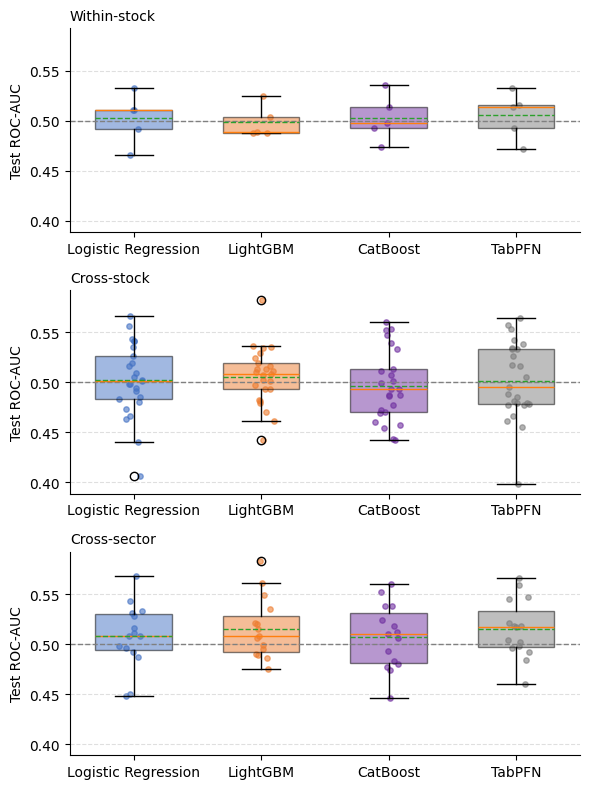

In [8]:
### distribution of ROC-AUC over the evaluations (boxplot as in the Lecture 2 notebook) ###

colors = ["#4472C4", "#ED7D31", "#7030A0", "#7F7F7F"]
fig, axes = plt.subplots(3, 1, figsize=(6, 8), sharey=True)
for ax, setting in zip(axes, SETTINGS):
    values = [per_eval[(per_eval["setting"] == setting) & (per_eval["features"] == "A")
                       & (per_eval["model"] == m)]["auc"].to_numpy() for m in MODELS]
    box = ax.boxplot(values, tick_labels=[NAMES[m] for m in MODELS], patch_artist=True,
                     showmeans=True, meanline=True, widths=0.6)
    for patch, color in zip(box["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.5)
    # individual evaluations as dots
    rng_vis = np.random.default_rng(0)
    for x0, (vals, color) in enumerate(zip(values, colors), start=1):
        ax.scatter(np.full(len(vals), x0) + rng_vis.normal(0, 0.05, len(vals)), vals, alpha=0.6, s=15, color=color)
    ax.axhline(0.5, color="grey", linestyle="--", linewidth=1)
    ax.set_title(NAMES[setting], loc="left", fontsize=10)
    ax.set_ylabel("Test ROC-AUC")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig("figures/auc_boxplot.png", dpi=300)
plt.show()

In [9]:
### Friedman test: do the models differ? (per setting and feature set, Bonferroni over the six tests) ###
### the models are ranked within each evaluation (1 = highest ROC-AUC) ###

friedman = []
for setting in SETTINGS:
    for feature_set in ["A", "B"]:
        rows = per_eval[(per_eval["setting"] == setting) & (per_eval["features"] == feature_set)]
        wide = rows.pivot(index=["held_out", "test_year"], columns="model", values="auc")[MODELS]
        statistic, p = stats.friedmanchisquare(*[wide[m] for m in MODELS])
        ranks = wide.rank(axis=1, ascending=False).mean()
        friedman.append({"setting": setting, "features": feature_set, "n": len(wide),
                         "chi2": statistic, "p": p,
                         **{f"rank_{m}": ranks[m] for m in MODELS}})

friedman = pd.DataFrame(friedman)

### Bonferroni correction for the six Friedman tests (3 settings x 2 feature sets), as in Lecture 2 ###
n_comparisons = len(friedman)
friedman["p_bonferroni"] = (friedman["p"] * n_comparisons).clip(upper=1.0)

friedman.to_csv("results/tests_friedman.csv", index=False)
friedman.round(3)

,setting,features,n,chi2,p,rank_lr,rank_lgbm,rank_cat,rank_tabpfn,p_bonferroni
0,within,A,5,6.120,0.106,3.000,3.400,1.800,1.800,0.635
1,within,B,5,3.480,0.323,2.800,3.000,1.600,2.600,1.000
2,cross_stock,A,25,2.952,0.399,2.400,2.400,2.880,2.320,1.000
3,cross_stock,B,25,2.424,0.489,2.480,2.200,2.560,2.760,1.000
4,cross_sector,A,15,5.000,0.172,2.800,2.067,2.933,2.200,1.000
5,cross_sector,B,15,0.200,0.978,2.467,2.600,2.400,2.533,1.000


In [10]:
### Wilcoxon signed-rank test with a Bonferroni correction within each group of tests ###

def wilcoxon_group(differences):
    """differences: {name: paired differences}. Returns one row per test, Bonferroni within the group."""
    rows = []
    n_comparisons = len(differences)
    for name, d in differences.items():
        statistic, p_val = stats.wilcoxon(d)
        p_bonferroni = p_val * n_comparisons
        p_bonferroni = 1.0 if p_bonferroni > 1.0 else p_bonferroni
        rows.append({"test": name, "n": len(d), "mean_difference": np.mean(d),
                     "W": statistic, "p": p_val, "p_bonferroni": p_bonferroni})
    return rows

wilcoxon = []

In [11]:
### each model against chance (ROC-AUC = 0.5) ###

for setting in SETTINGS:
    for feature_set in ["A", "B"]:
        rows = per_eval[(per_eval["setting"] == setting) & (per_eval["features"] == feature_set)]
        wide = rows.pivot(index=["held_out", "test_year"], columns="model", values="auc")
        group = {f"{m} vs chance": wide[m] - 0.5 for m in MODELS}
        for row in wilcoxon_group(group):
            wilcoxon.append({"question": "model vs chance", "setting": setting, "features": feature_set, **row})

In [12]:
### RQ4: feature set B against feature set A ###

for setting in SETTINGS:
    rows = per_eval[per_eval["setting"] == setting]
    group = {}
    for m in MODELS:
        wide = rows[rows["model"] == m].pivot(index=["held_out", "test_year"], columns="features", values="auc")
        group[f"{m}: B vs A"] = wide["B"] - wide["A"]
    for row in wilcoxon_group(group):
        wilcoxon.append({"question": "RQ4: B vs A", "setting": setting, "features": "B vs A", **row})

In [13]:
### RQ2 and RQ3: the within-stock model against the cross model, on the same test stocks and test year ###
### ROC-AUC from the seed-averaged predictions, so that both sides are computed in the same way ###

def auc_on(rows):
    return roc_auc_score(rows["Target"], rows["proba"])

matched = []
for setting in ["cross_stock", "cross_sector"]:
    for feature_set in ["A", "B"]:
        for m in MODELS:
            cross = predictions[(predictions["setting"] == setting) & (predictions["features"] == feature_set)
                                & (predictions["model"] == m)]
            within = predictions[(predictions["setting"] == "within") & (predictions["features"] == feature_set)
                                 & (predictions["model"] == m)]
            for (held_out, test_year), rows in cross.groupby(["held_out", "test_year"]):
                same = within[(within["test_year"] == test_year) & within["Ticker"].isin(rows["Ticker"].unique())]
                matched.append({"setting": setting, "features": feature_set, "model": m,
                                "held_out": held_out, "test_year": test_year,
                                "auc_within": auc_on(same), "auc_cross": auc_on(rows)})
matched = pd.DataFrame(matched)
matched["difference"] = matched["auc_cross"] - matched["auc_within"]
matched.to_csv("results/table_matched.csv", index=False)

for (setting, feature_set), rows in matched.groupby(["setting", "features"]):
    group = {f"{m}: cross vs within": rows[rows["model"] == m]["difference"].to_numpy() for m in MODELS}
    for row in wilcoxon_group(group):
        wilcoxon.append({"question": "RQ2/RQ3: cross vs within", "setting": setting, "features": feature_set, **row})

(matched.groupby(["setting", "features", "model"])[["auc_within", "auc_cross", "difference"]]
 .mean().round(4))

auc_within  auc_cross  difference
setting      features model                                    
cross_sector A        cat         0.5122     0.5073     -0.0049
                      lgbm        0.5046     0.5155      0.0108
                      lr          0.5095     0.5078     -0.0016
                      tabpfn      0.5134     0.5151      0.0017
             B        cat         0.5128     0.5079     -0.0048
                      lgbm        0.5056     0.5055     -0.0001
                      lr          0.5099     0.5121      0.0022
                      tabpfn      0.5115     0.5122      0.0007
cross_stock  A        cat         0.5011     0.4966     -0.0046
                      lgbm        0.5012     0.5058      0.0046
                      lr          0.5051     0.5019     -0.0032
                      tabpfn      0.5093     0.5019     -0.0074
             B        cat         0.5125     0.5033     -0.0092
                      lgbm        0.5003     0.5104      0.0101
                      lr          0.5075     0.5025     -0.0050
                      tabpfn      0.5084     0.5012     -0.0072

In [14]:
### all Wilcoxon tests ###

wilcoxon = pd.DataFrame(wilcoxon)
wilcoxon.to_csv("results/tests_wilcoxon.csv", index=False)
print(len(wilcoxon), "tests | p < 0.05 before correction:", (wilcoxon["p"] < 0.05).sum(),
      "| after Bonferroni:", (wilcoxon["p_bonferroni"] < 0.05).sum())
wilcoxon.round(4)

52 tests | p < 0.05 before correction: 0 | after Bonferroni: 0


,question,setting,features,test,n,mean_difference,W,p,p_bonferroni
0,model vs chance,within,A,lr vs chance,5,0.0024,6.0,0.8125,1.0000
1,model vs chance,within,A,lgbm vs chance,5,-0.0015,6.0,0.8125,1.0000
2,model vs chance,within,A,cat vs chance,5,0.0027,7.0,1.0000,1.0000
3,model vs chance,within,A,tabpfn vs chance,5,0.0053,5.0,0.6250,1.0000
4,model vs chance,within,B,lr vs chance,5,0.0024,6.0,0.8125,1.0000
5,model vs chance,within,B,lgbm vs chance,5,-0.0010,7.0,1.0000,1.0000
6,model vs chance,within,B,cat vs chance,5,0.0042,5.0,0.6250,1.0000
7,model vs chance,within,B,tabpfn vs chance,5,0.0037,5.0,0.6250,1.0000
8,model vs chance,cross_stock,A,lr vs chance,25,0.0019,147.0,0.6915,1.0000
9,model vs chance,cross_stock,A,lgbm vs chance,25,0.0058,120.0,0.2635,1.0000
